# Varanasi 5-km Static-Conditioned ConvLSTM

**Goal:** 30-minute-ahead rainfall prediction on the 7×11 (77-cell) Varanasi 5-km grid.

- 12-hour history = 24 × 30-minute steps
- ERA5 + IMERG dynamic features
- WorldCover + GHSL + DEM static conditioning
- Train: Jan–Sep 2024
- Validation: Oct–Dec 2024
- Final test: 2025
- GPU training when available


In [10]:
!nvidia-smi
!pip -q install -r /content/varanasi_convlstm/requirements.txt


Tue Oct  6 19:53:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 592.82                 Driver Version: 592.82         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   51C    P4              7W /   50W |       0MiB /   8188MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Could not open requirements file: [Errno 2] No such file or directory: '/content/varanasi_convlstm/requirements.txt'


In [11]:
# Varanasi 5-km Static-Conditioned ConvLSTM
# Colab-ready notebook. All datasets are bundled in data/.

from pathlib import Path
import pandas as pd
from IPython.display import display, Image

from pathlib import Path

# VS Code / local project
PROJECT = Path.cwd()
DATA = PROJECT / "data"

print("Project:", PROJECT)
print("Data folder:", DATA)
print("Data exists:", DATA.exists())
OUTPUT = PROJECT / 'outputs'

print("Project:", PROJECT)
print("Dataset files:", len(list(DATA.glob("*.csv"))))

required = [
  "ERA5_Varanasi_5km_2024_Q1.csv",
  "ERA5_Varanasi_5km_2024_Q2.csv",
  "ERA5_Varanasi_5km_2024_Q3.csv",
  "ERA5_Varanasi_5km_2024_Q4.csv",
  "ERA5_Varanasi_5km_2025_Q1(1).csv",
  "ERA5_Varanasi_5km_2025_Q2(1).csv",
  "ERA5_Varanasi_5km_2025_Q3(1).csv",
  "ERA5_Varanasi_5km_2025_Q4(1).csv",
  "IMERG_Varanasi_5km_2024_Q1_ERA5_aligned.csv",
  "IMERG_Varanasi_5km_2024_Q2_ERA5_aligned.csv",
  "IMERG_Varanasi_5km_2024_Q3_ERA5_aligned.csv",
  "IMERG_Varanasi_5km_2024_Q4_ERA5_aligned.csv",
  "IMERG_Varanasi_5km_2025_Q1_ERA5_aligned.csv",
  "IMERG_Varanasi_5km_2025_Q2_ERA5_aligned.csv",
  "IMERG_Varanasi_5km_2025_Q3_ERA5_aligned.csv",
  "IMERG_Varanasi_5km_2025_Q4_ERA5_aligned.csv",
  "WorldCover_5km_IMERG_grid_aligned.csv",
  "GHSL_5km_IMERG_grid_aligned.csv",
  "DEM_5km_IMERG_grid_aligned.csv"
]
missing = [f for f in required if not (DATA / f).exists()]
if missing:
    raise FileNotFoundError(missing)

print("All 19 datasets found.")


Project: c:\Users\MITRAVINDA\Downloads\Varanasi_5km_ConvLSTM_Colab_Project
Data folder: c:\Users\MITRAVINDA\Downloads\Varanasi_5km_ConvLSTM_Colab_Project\data
Data exists: True
Project: c:\Users\MITRAVINDA\Downloads\Varanasi_5km_ConvLSTM_Colab_Project
Dataset files: 19
All 19 datasets found.


## Dataset sanity check
This reads a small sample before full training.

In [12]:
sample = pd.read_csv(DATA / 'IMERG_Varanasi_5km_2024_Q1_ERA5_aligned.csv', nrows=10)
print('IMERG columns:')
print(sample.columns.tolist())
print('\nSanity check: PASSED')


IMERG columns:
['system:index', 'grid_id', 'latitude', 'longitude', 'precipitation_mm_hr', 'timestamp', '.geo']

Sanity check: PASSED


## Train the model
Run this cell after enabling a GPU in **Runtime → Change runtime type → T4 GPU**.

In [13]:
%cd /content/varanasi_convlstm
!python train_varanasi_convlstm.py


[WinError 3] The system cannot find the path specified: '/content/varanasi_convlstm'
c:\Users\MITRAVINDA\Downloads\Varanasi_5km_ConvLSTM_Colab_Project

VARANASI 5-KM CONVLSTM TRAINING

Project directory:
C:\Users\MITRAVINDA\Downloads\Varanasi_5km_ConvLSTM_Colab_Project

Data directory:
C:\Users\MITRAVINDA\Downloads\Varanasi_5km_ConvLSTM_Colab_Project\data

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA: 13.0
Found all 19 required CSV files.

Reading reference grid:
C:\Users\MITRAVINDA\Downloads\Varanasi_5km_ConvLSTM_Colab_Project\data\ERA5_Varanasi_5km_2024_Q1.csv

Total rows in reference file: 167629
Unique grid cells found: 77

VARANASI SPATIAL GRID
Rows  : 7
Cols  : 11
Cells : 77

Grid layout:

G0000 | G0007 | G0014 | G0021 | G0028 | G0035 | G0042 | G0049 | G0056 | G0063 | G0070
G0001 | G0008 | G0015 | G0022 | G0029 | G0036 | G0043 | G0050 | G0057 | G0064 | G0071
G0002 | G0009 | G0016 | G0023 | G0030 | G0037 | G0044 | G0051 | G0058 | G0065 | G0072
G0003 | G0010 | G0017 | 


Training: 100%|█████████▉| 410/411 [00:25<00:00, 16.08it/s, loss=0.00699]
                                                                         

Training: 100%|█████████▉| 410/411 [00:27<00:00, 16.72it/s, loss=0.37219]
                                                                         

Training: 100%|█████████▉| 410/411 [00:23<00:00, 17.84it/s, loss=0.01561]
                                                                         

Training: 100%|█████████▉| 409/411 [00:23<00:00, 16.16it/s, loss=0.00708]
                                                                         

Training: 100%|█████████▉| 410/411 [00:22<00:00, 17.26it/s, loss=0.00175]
                                                                         

Training: 100%|█████████▉| 410/411 [00:25<00:00, 15.76it/s, loss=0.16177]
                                                                         

Training: 100%|██████████| 411/411 [00:23<00:00, 18.69it/s, loss=0.13474]
                               

## Display generated visualizations

00_model_architecture.png


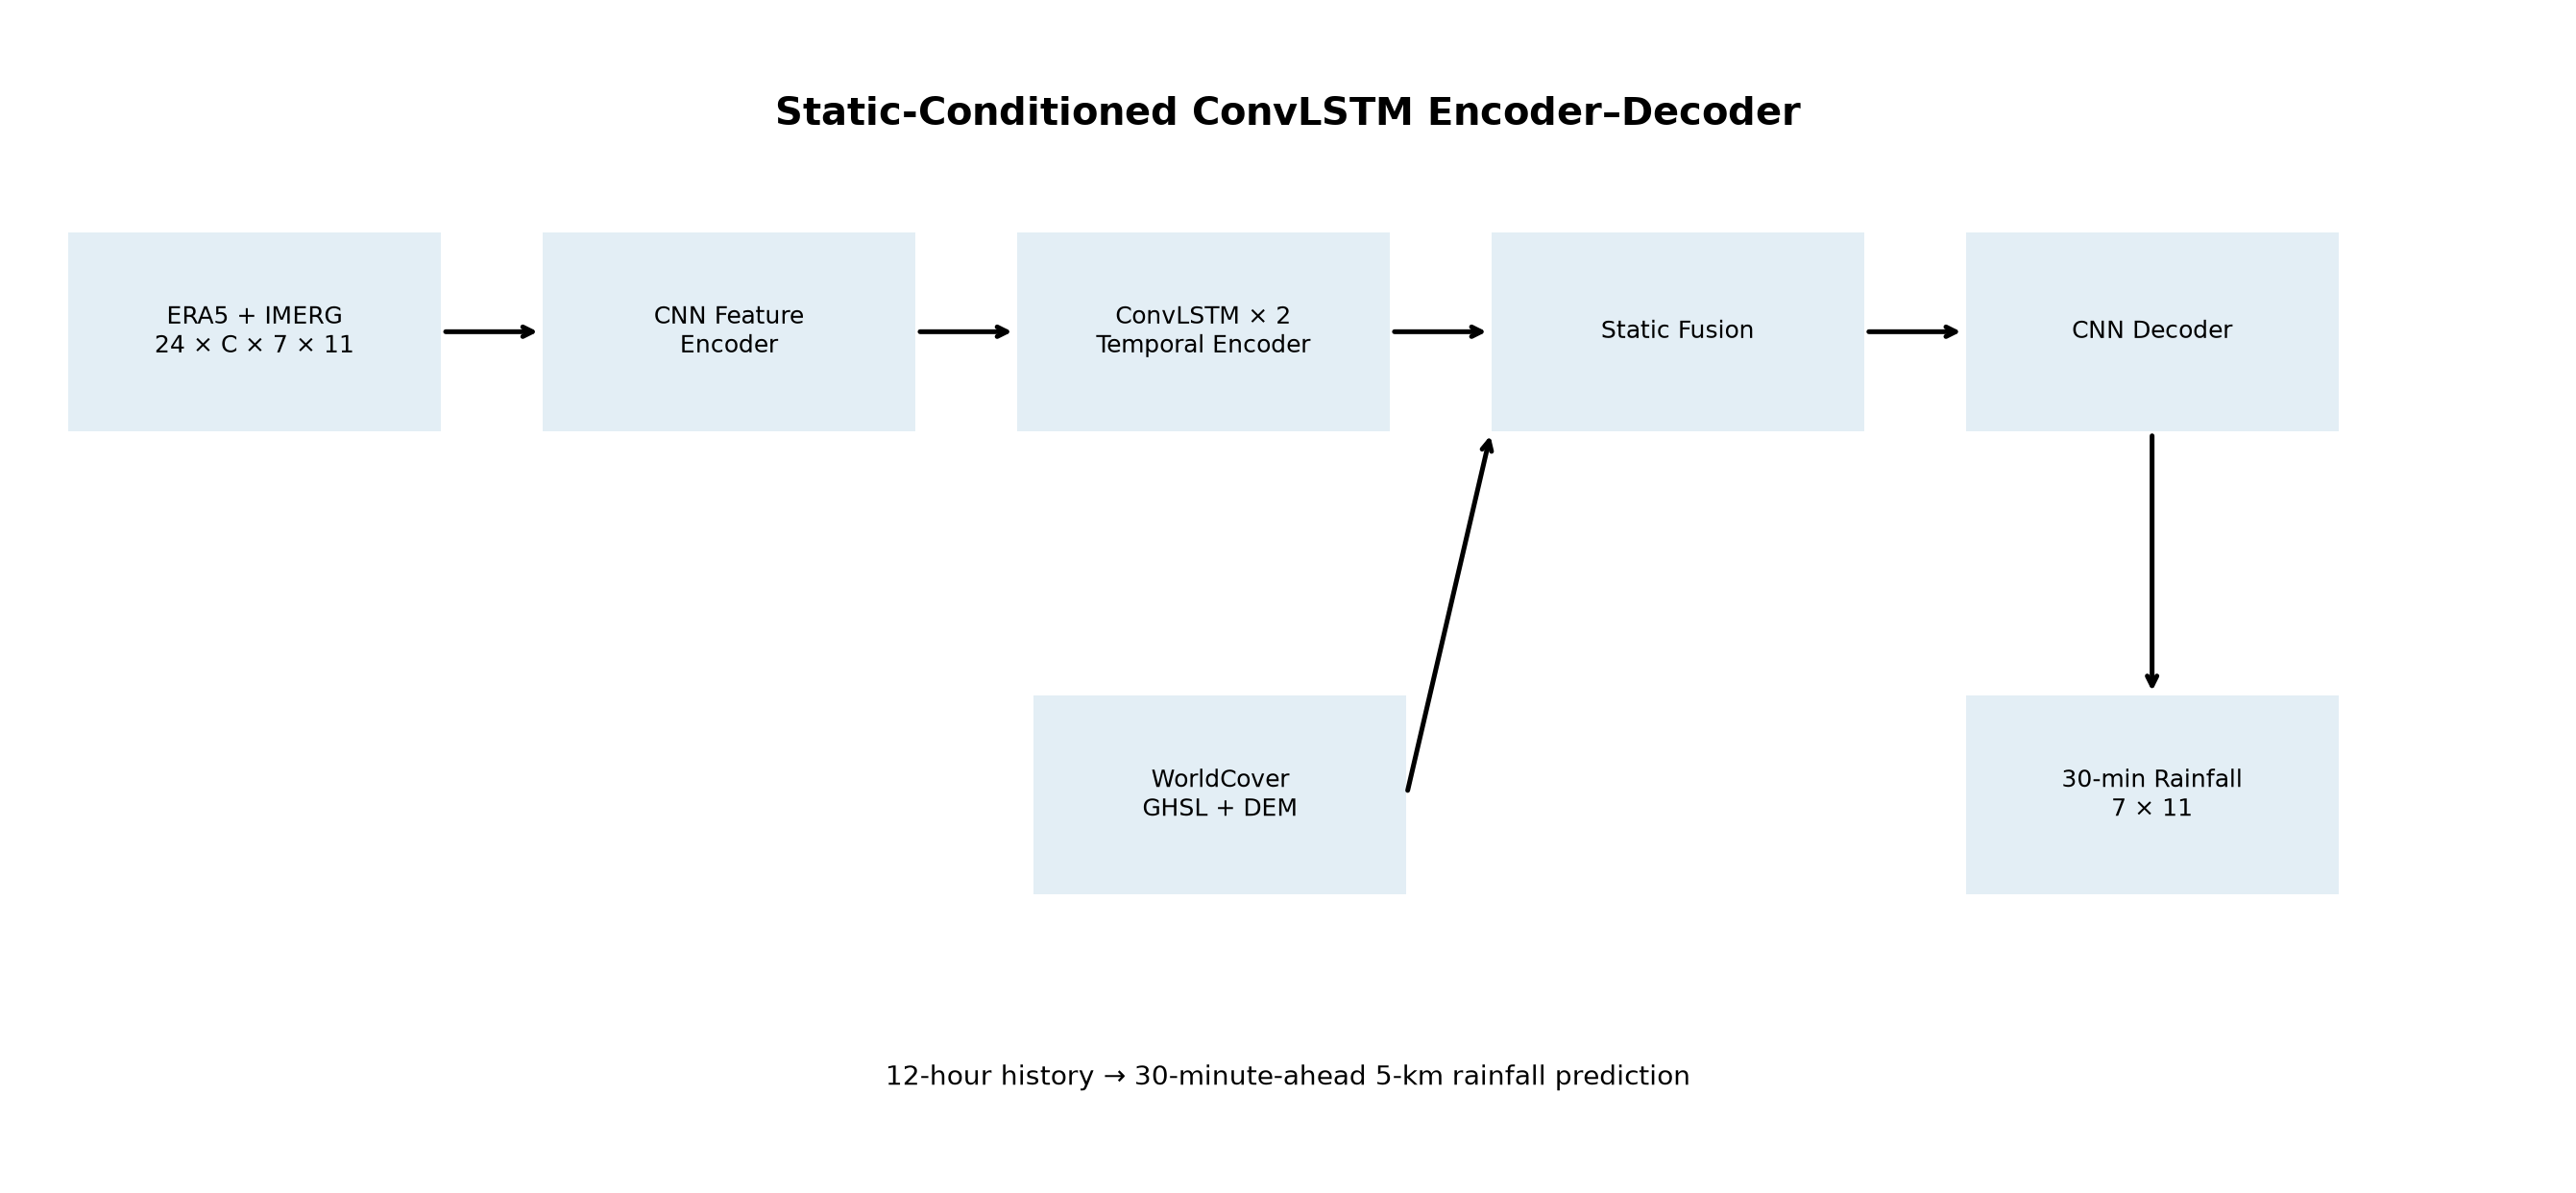

01_spatial_grid.png


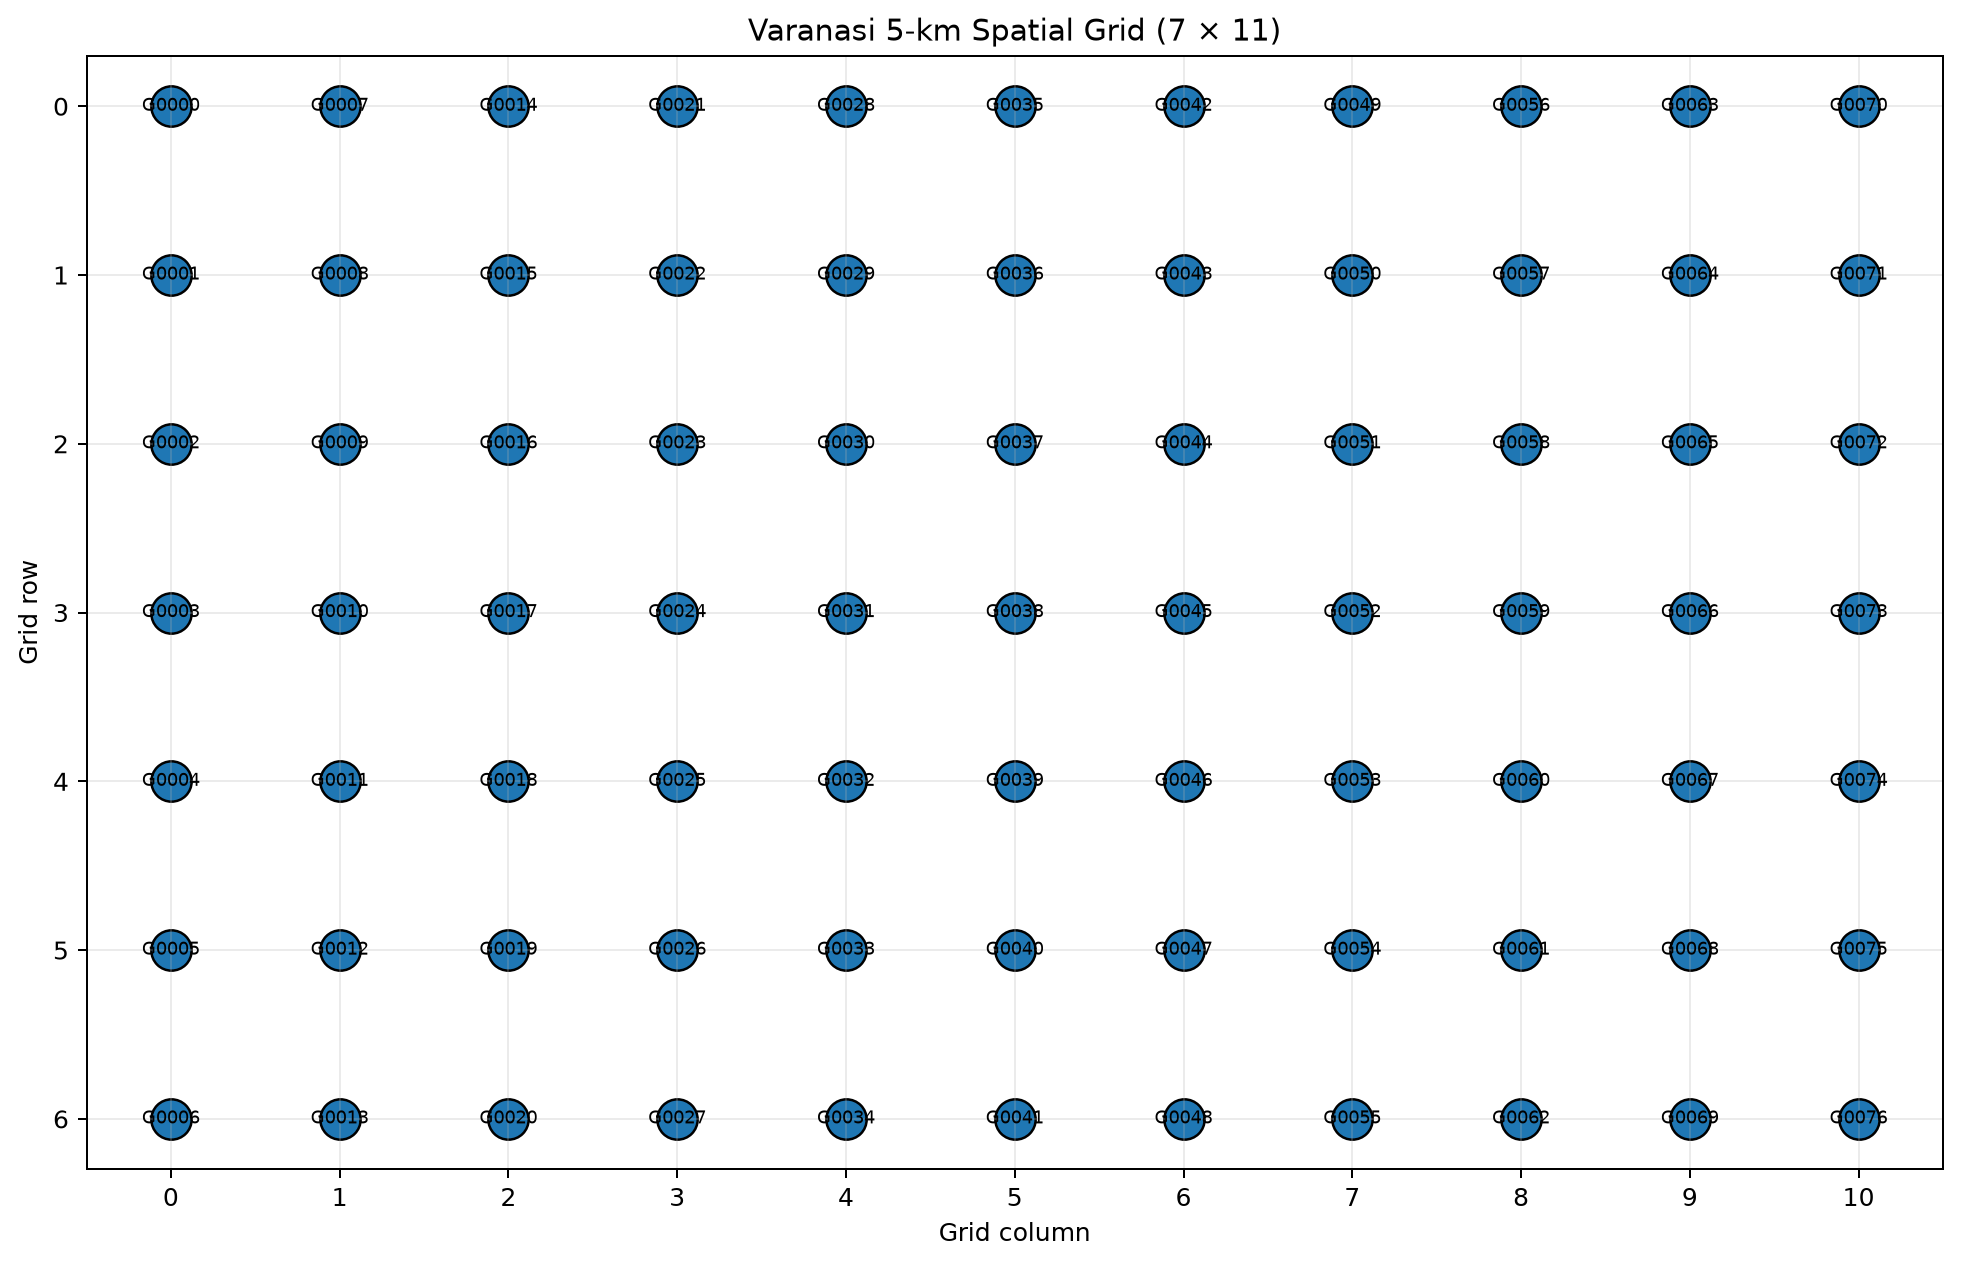

02_static_feature_maps.png


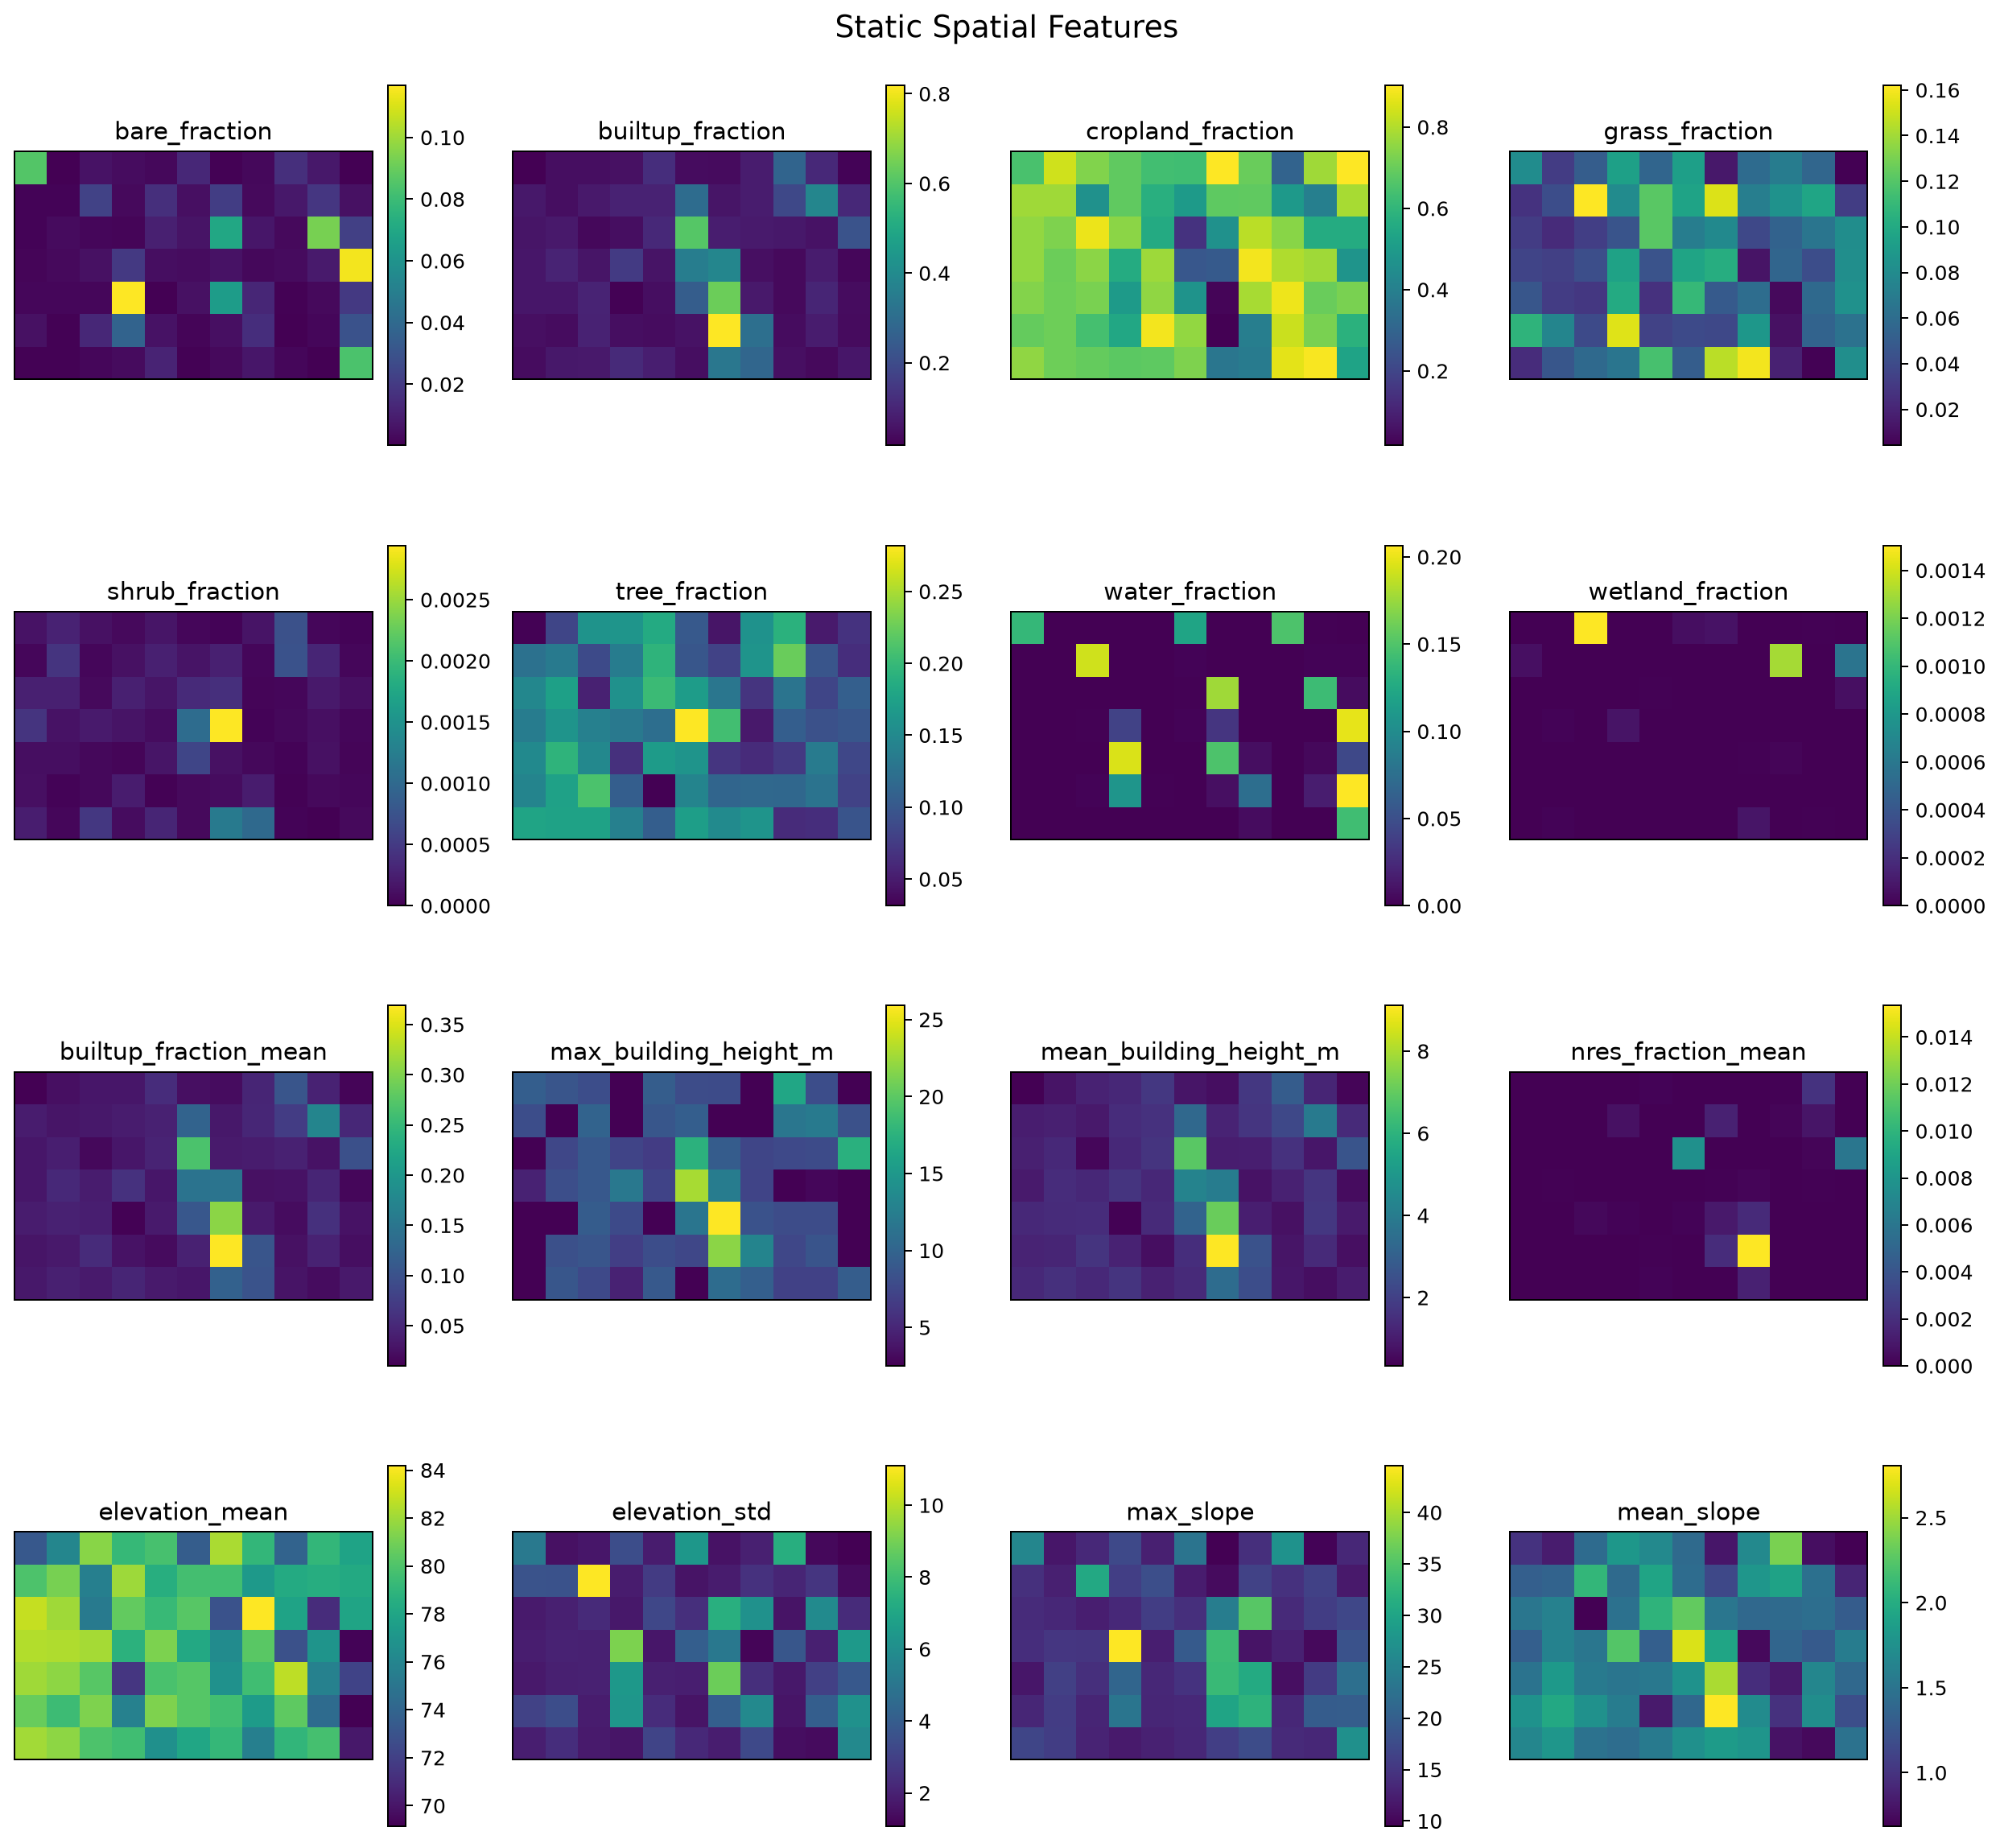

03_training_curves.png


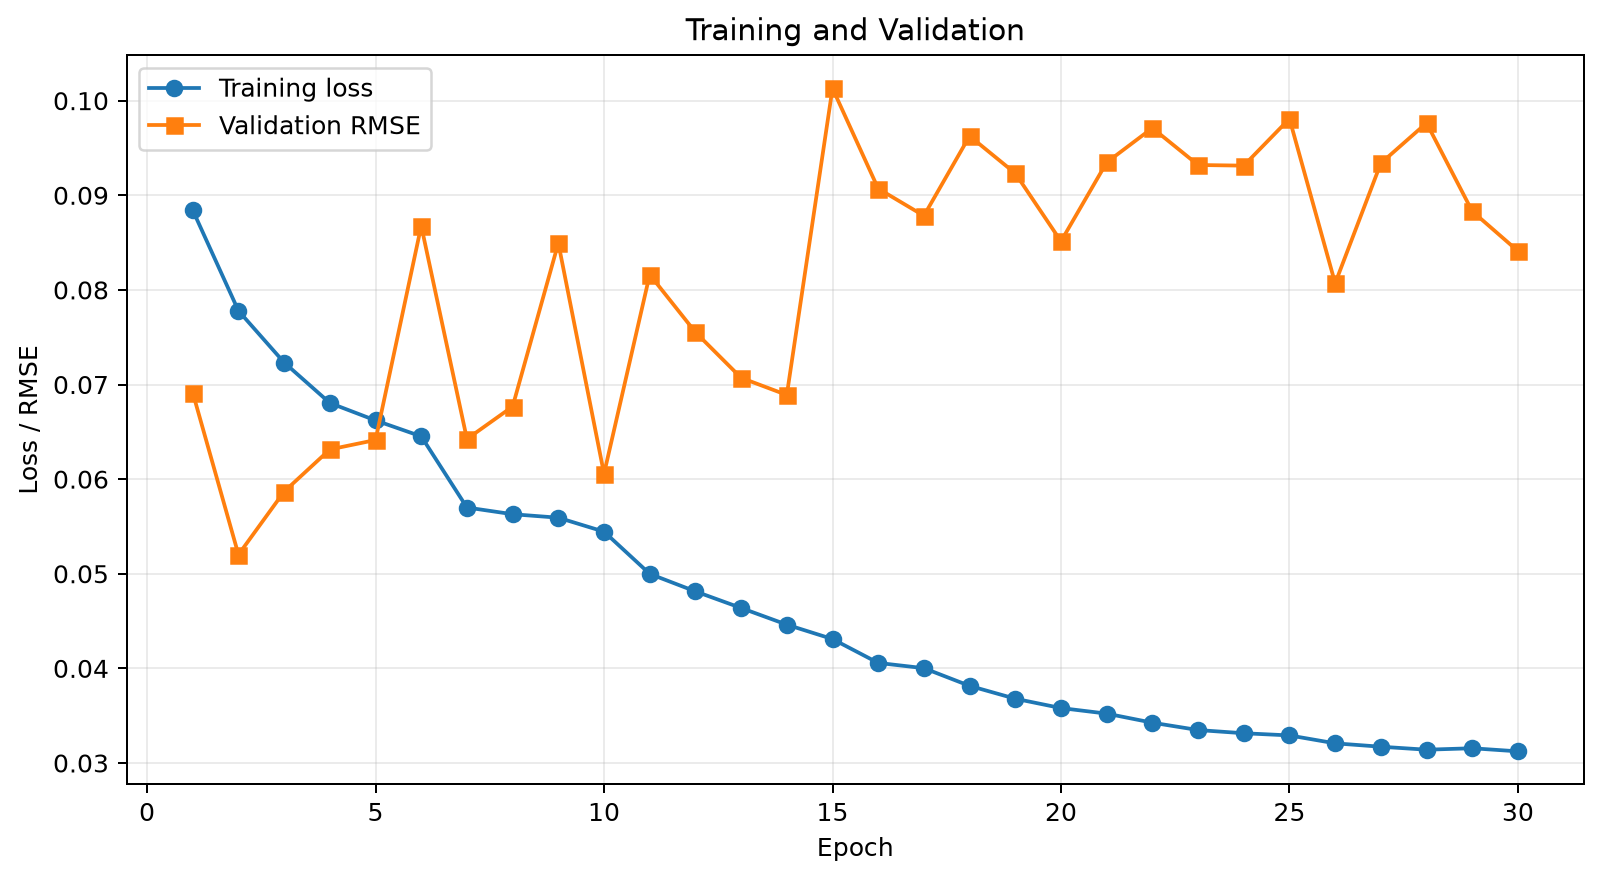

04_rain_event_f1.png


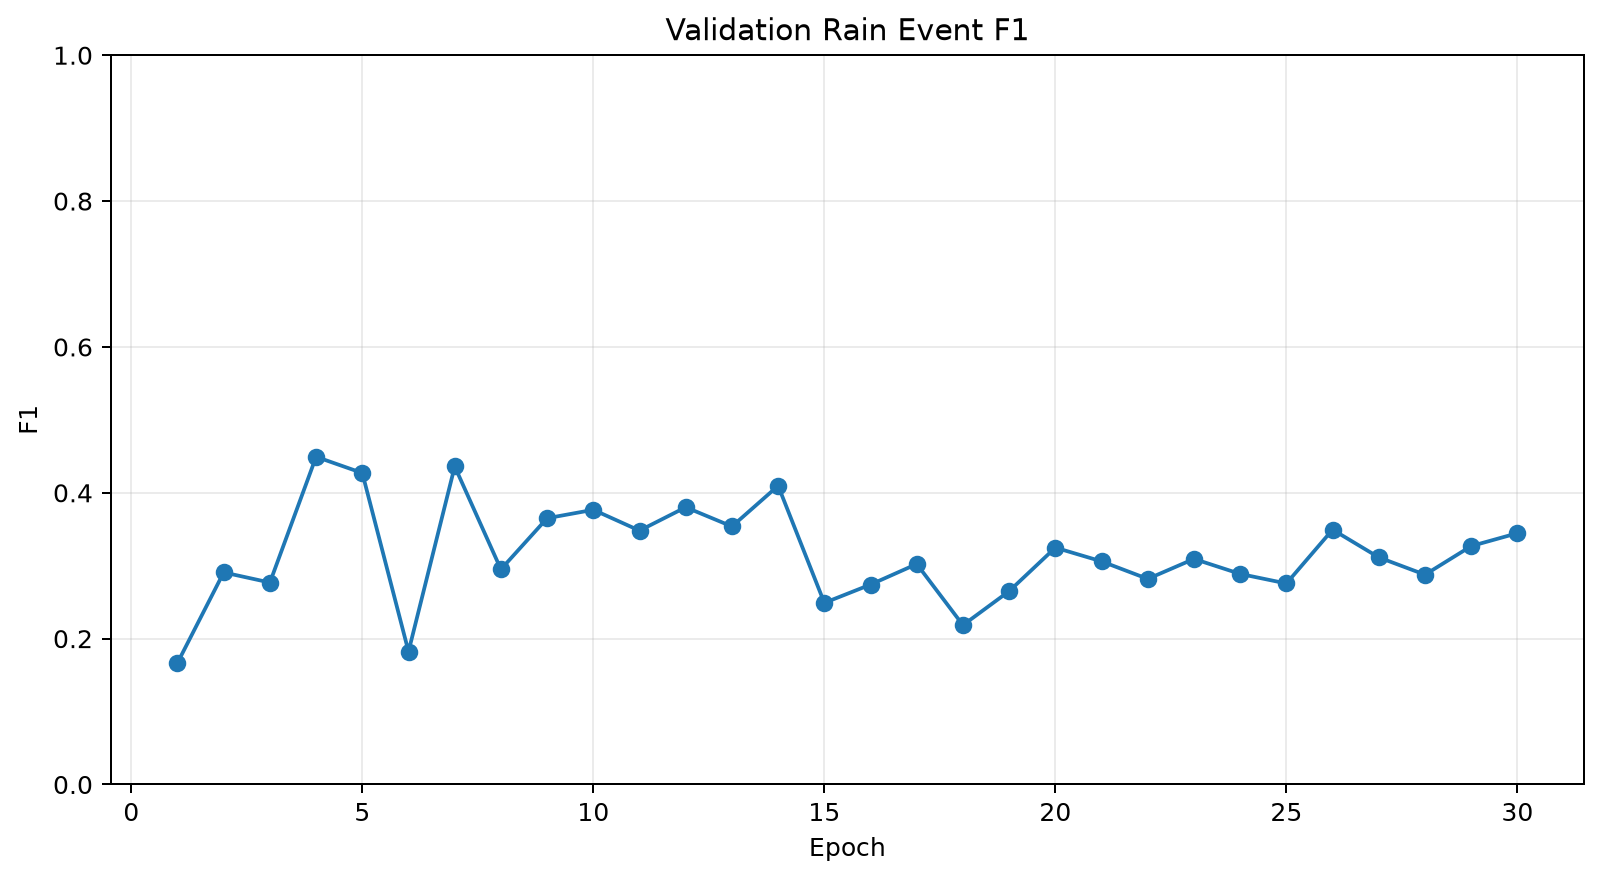

05_actual_vs_predicted_map.png


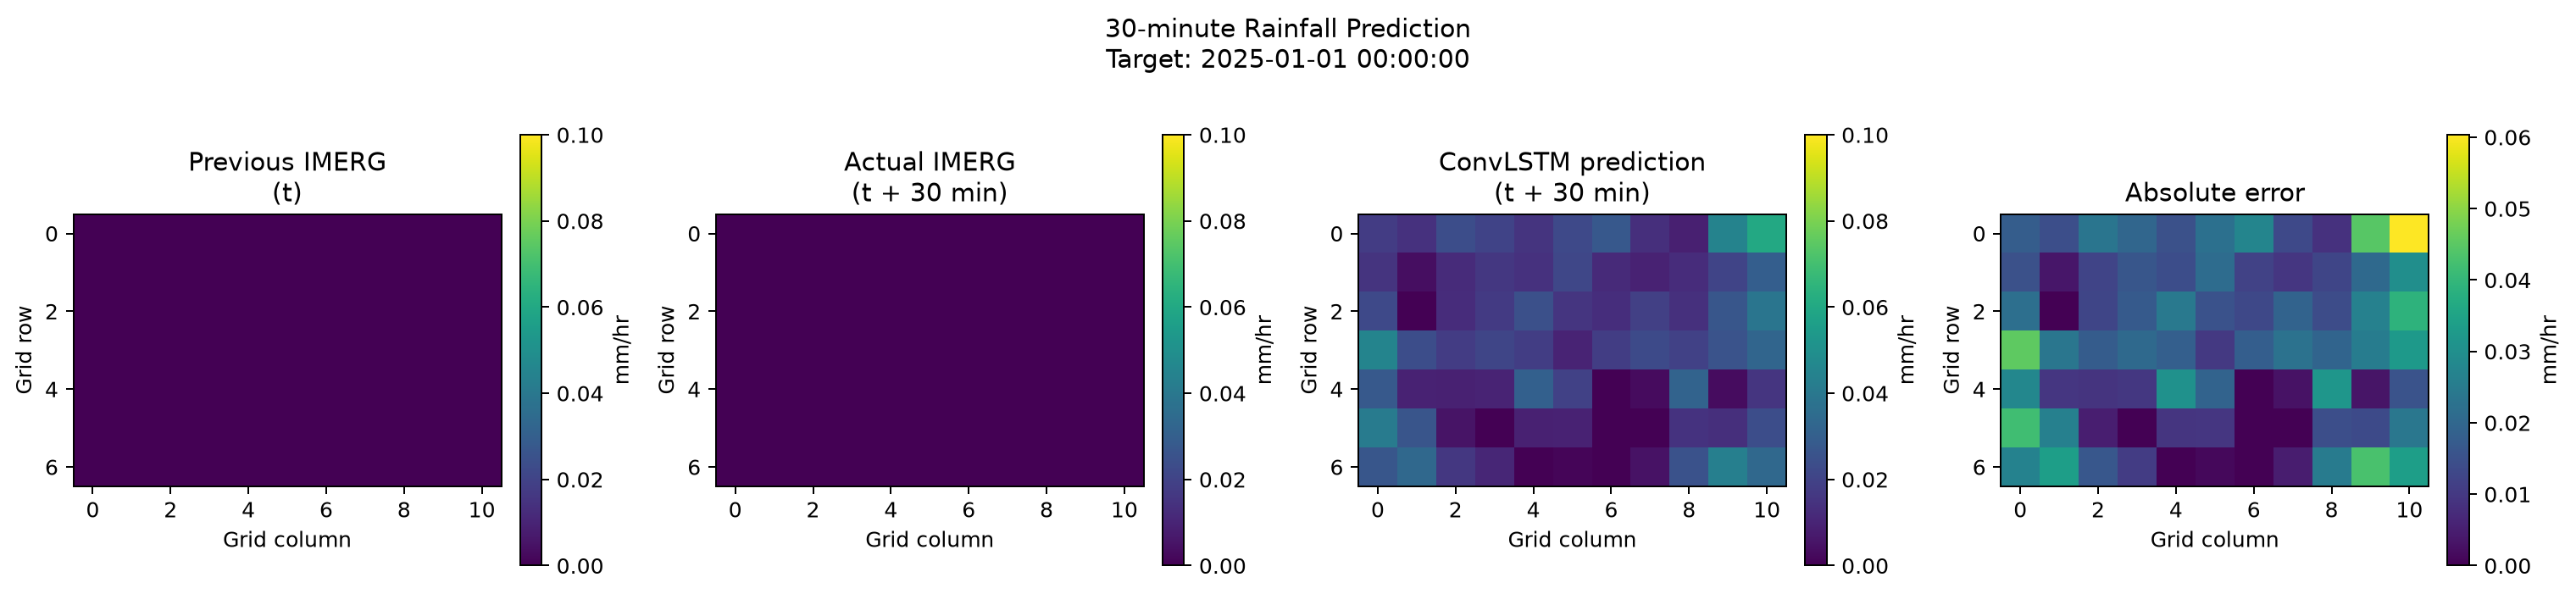

06_actual_vs_predicted_scatter.png


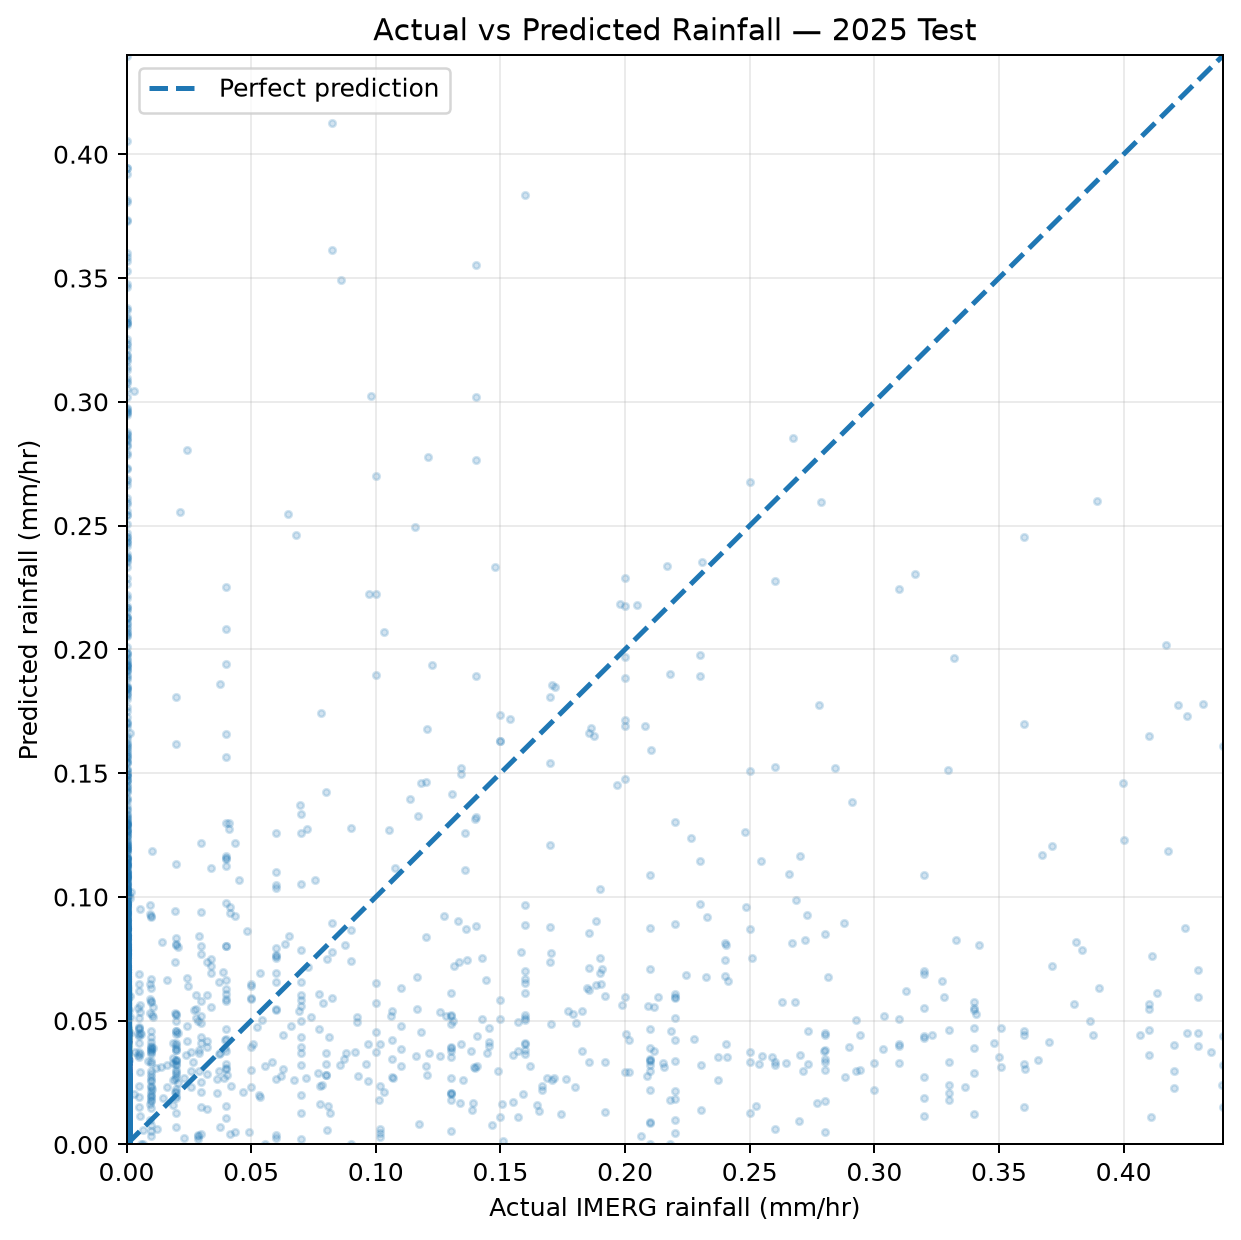

In [14]:
for name in [
    '00_model_architecture.png',
    '01_spatial_grid.png',
    '02_static_feature_maps.png',
    '03_training_curves.png',
    '04_rain_event_f1.png',
    '05_actual_vs_predicted_map.png',
    '06_actual_vs_predicted_scatter.png'
]:
    p = OUTPUT / name
    if p.exists():
        print(name)
        display(Image(filename=str(p), width=1000))


In [15]:
metrics = OUTPUT / 'final_2025_test_metrics.csv'
if metrics.exists():
    display(pd.read_csv(metrics))
else:
    print('Run the training cell first.')


,MAE_mm_hr,RMSE_mm_hr,RainEvent_Precision,RainEvent_Recall,RainEvent_F1
0,0.144758,0.657791,0.360967,0.874224,0.510959
